# 🚀 Practice Day 63

**📅 Date:** 2026-11-06  
📁 Category: Phase 3 · 시각화 스토리텔링(Seaborn) (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Use Seaborn to visually tell the story of what drives wine price — aging, growing region, and quality score
  (Seaborn으로 무엇이 와인 가격을 좌우하는지 — 숙성기간·산지·품질점수 — 시각적으로 스토리텔링하기)
- Quantify how strongly aging correlates with quality, how price differs across regions, and how quality relates to price
  (숙성기간과 품질점수의 상관관계, 산지별 가격 차이, 품질점수와 가격의 관계를 정량적으로 파악하기)

---
# 📂 Dataset

**Dataset Name:** Vintner's Table — Wine Quality Data / Vintner's Table — 와인 품질 평가 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 280 wines (single table) across 6 growing regions (Bordeaux, Tuscany, Napa Valley, Rioja, Mendoza, Barossa). Includes years of aging, a quality score on a 0-100 scale, and price. Price is in USD per bottle. Clean — no missing values or duplicates. Several variables jointly shape price, so the focus is on using Seaborn to visualize those relationships and build a narrative.
(6개 산지(Bordeaux/Tuscany/Napa Valley/Rioja/Mendoza/Barossa)의 와인 280개 데이터입니다(단일 테이블). 숙성연수, 0~100점 척도의 품질점수, 가격을 포함합니다. 가격은 병당 USD이며 결측치·중복 없이 깨끗합니다. 여러 변수가 함께 가격에 영향을 미치는 구조라, Seaborn으로 관계를 시각화하며 스토리를 풀어가는 데 초점을 둡니다.)

## Dataset Preview

In [33]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate wine quality data across 6 growing regions ---
n = 280
regions = ['Bordeaux', 'Tuscany', 'Napa Valley', 'Rioja', 'Mendoza', 'Barossa']
region_w = [0.20, 0.16, 0.18, 0.14, 0.16, 0.16]
region_price_premium = {'Bordeaux': 1.35, 'Tuscany': 1.15, 'Napa Valley': 1.30, 'Rioja': 0.95, 'Mendoza': 0.75, 'Barossa': 1.0}

region_choice = rng.choice(regions, size=n, p=region_w)
aging_years = np.clip(rng.exponential(4, n), 0.5, 15).round(1)

# quality score (0-100 scale) driven mainly by aging, plus noise
quality_score = 78 + aging_years * 1.15 + rng.normal(0, 2.2, n)
quality_score = np.clip(quality_score, 65, 98).round(1)

# price driven by quality score and a region premium
base_price = 15 + (quality_score - 78) * 2.2  # USD per bottle
price = base_price * np.array([region_price_premium[r] for r in region_choice]) * rng.normal(1.0, 0.07, n)
price = price.round(1)  # nearest $0.10

df = pd.DataFrame({
    'wine_id': [f'W{str(i+1).zfill(4)}' for i in range(n)],
    'region': region_choice,
    'aging_years': aging_years,
    'quality_score': quality_score,
    'price': price
})

df.head(10)


,wine_id,region,aging_years,quality_score,price
0,W0001,Mendoza,0.5,80.1,16.0
1,W0002,Napa Valley,0.5,80.0,20.5
2,W0003,Barossa,2.0,81.1,22.4
3,W0004,Mendoza,0.5,79.8,15.8
4,W0005,Bordeaux,1.3,80.1,24.4
5,W0006,Barossa,3.0,85.9,31.5
6,W0007,Mendoza,0.5,78.4,11.3
7,W0008,Mendoza,1.4,78.9,11.9
8,W0009,Bordeaux,6.3,83.6,36.0
9,W0010,Napa Valley,0.5,76.3,16.1


## Dataset Information

In [34]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   wine_id        280 non-null    str    
 1   region         280 non-null    str    
 2   aging_years    280 non-null    float64
 3   quality_score  280 non-null    float64
 4   price          280 non-null    float64
dtypes: float64(3), str(2)
memory usage: 11.1 KB

Shape: (280, 5)


,wine_id,region,aging_years,quality_score,price
count,280,280,280.000000,280.000000,280.000000
unique,280,6,NaN,NaN,NaN
top,W0001,Bordeaux,NaN,NaN,NaN
freq,1,66,NaN,NaN,NaN
mean,NaN,NaN,4.009643,82.454286,27.434643
std,NaN,NaN,3.735447,4.722286,13.342770
min,NaN,NaN,0.500000,73.300000,4.400000
25%,NaN,NaN,1.100000,79.300000,17.650000
50%,NaN,NaN,2.650000,81.500000,24.400000
75%,NaN,NaN,5.500000,84.600000,34.225000


---
# ❓ Business Questions

1. **(Analysis)** How strong is the correlation between years of aging and quality score?
   (숙성연수와 품질점수의 상관관계는 얼마나 강한가?)
2. **(Analysis)** How does average price differ across the six wine regions?
   (산지별 평균 가격은 어떻게 다른가?)
3. **(Analysis)** How strong is the correlation between quality score and price?
   (품질점수와 가격의 상관관계는 얼마나 강한가?)
4. **(Visualization)** Show the relationship between aging years and quality score, broken out by region.
   (숙성연수와 품질점수의 관계를 산지별로 나누어 보면?)
5. **(Visualization)** Show how the price distribution itself differs across regions.
   (산지별 가격 분포 자체는 어떻게 다른가?)

---
# 🔍 Data Cleaning Check


In [35]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
wine_id          0
region           0
aging_years      0
quality_score    0
price            0
dtype: int64

Duplicate rows: 0

Dtypes
wine_id              str
region               str
aging_years      float64
quality_score    float64
price            float64
dtype: object

Column names
['wine_id', 'region', 'aging_years', 'quality_score', 'price']

Text columns — unique counts
wine_id    280
region       6
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How strong is the correlation between years of aging and quality score? (숙성연수와 품질점수의 상관관계는?)

**Result:**  
The correlation between aging years and quality score is **0.886**.  
(숙성연수와 품질점수의 상관계수는 **0.886**입니다.)  

**Insight:**  
The scatter points follow one rising line, so the relationship is strong and positive.  
(산점도의 점들이 오르는 직선 하나를 따라 모여 있어, 강한 양의 관계입니다.)

In [36]:
# Question 1: correlation between aging_years and quality_score
df['aging_years'].corr(df['quality_score'])

np.float64(0.8860872055979502)

<Axes: xlabel='aging_years', ylabel='quality_score'>

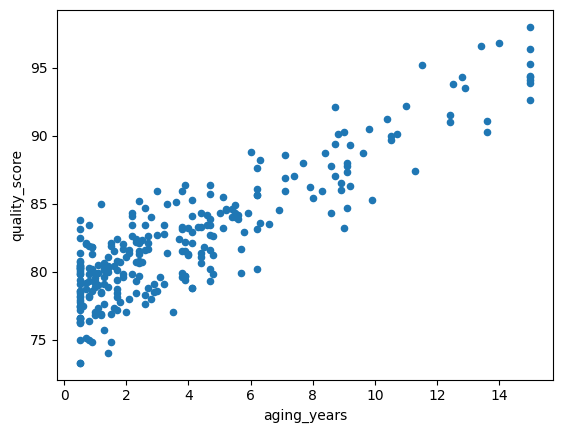

In [37]:
df.plot.scatter(x='aging_years', y='quality_score')

## Question 2

**Question:** How does average price differ across the six wine regions? (산지별 평균 가격은 어떻게 다른가?)

**Result:**  
Bordeaux has the highest average price at **$34.03**, and Mendoza the lowest at **$19.39**.  
(Bordeaux의 평균 가격이 **$34.03**으로 가장 높고, Mendoza가 **$19.39**로 가장 낮습니다.)  

**Insight:**  
Bordeaux averages **$14.64** more per bottle than Mendoza, and Napa Valley is second at **$32.48**.  
(Bordeaux는 Mendoza보다 병당 평균 **$14.64** 높고, 2위는 Napa Valley로 **$32.48**입니다.)

In [38]:
# Question 2: average price by region
avg_price_by_region = df.groupby(['region'])['price'].mean().sort_values(ascending=False).round(2)

avg_price_by_region

region
Bordeaux       34.03
Napa Valley    32.48
Tuscany        26.89
Rioja          24.86
Barossa        23.30
Mendoza        19.39
Name: price, dtype: float64

## Question 3

**Question:** How strong is the correlation between quality score and price? (품질점수와 가격의 상관관계는?)

**Result:**  
The correlation between quality score and price is **0.883**.  
(품질점수와 가격의 상관계수는 **0.883**입니다.)  

**Insight:**  
It is nearly the same strength as aging and quality (**0.886**), and the scatter follows a straight line.  
(숙성연수와 품질점수의 상관(**0.886**)과 거의 같은 강도이고, 산점도는 직선을 따릅니다.)

In [39]:
# Question 3: correlation between quality_score and price
df['quality_score'].corr(df['price'])

np.float64(0.8832838626679488)

<Axes: xlabel='quality_score', ylabel='price'>

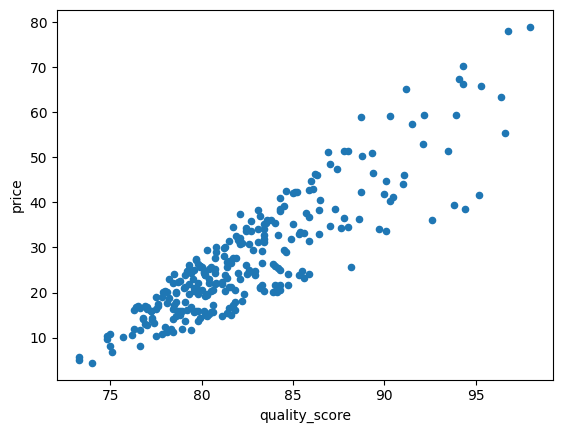

In [40]:
df.plot.scatter(x='quality_score', y='price')

---
# 📈 Visualization

**Chart 1:** Scatter plot with regression line (Seaborn) — aging years vs quality score, colored by region (Seaborn 산점도+회귀선: 숙성연수 vs 품질점수, 산지별 색상 구분)

*Interpretation:*  
Quality score rises with aging years along the red line, and the points of all six regions are mixed around it.  
(품질점수는 숙성연수와 함께 빨간 선을 따라 오르고, 여섯 산지의 점이 그 주변에 섞여 있습니다.)  

---

**Chart 2:** Box plot or violin plot (Seaborn) — price distribution by region (Seaborn 박스플롯/바이올린플롯: 산지별 가격 분포)

*Interpretation:*  
Bordeaux has the highest box and Mendoza the lowest and narrowest, in the same order as the averages. Napa Valley has the highest outliers, near **$80**.  
(Bordeaux 박스가 가장 높고 Mendoza가 가장 낮고 좁으며, 평균과 같은 순서입니다. Napa Valley의 이상치가 **$80** 근처로 가장 높습니다.)


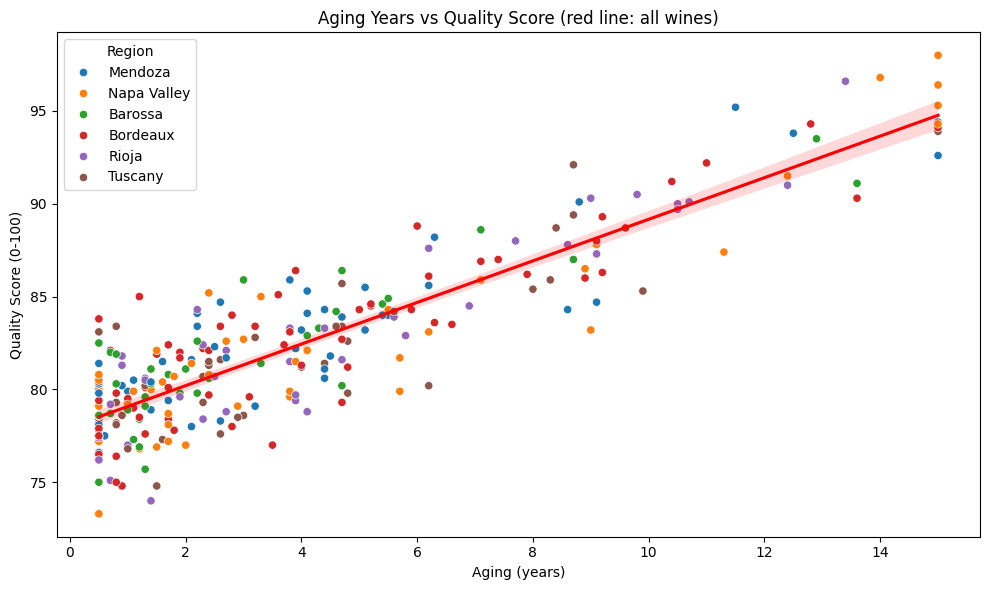

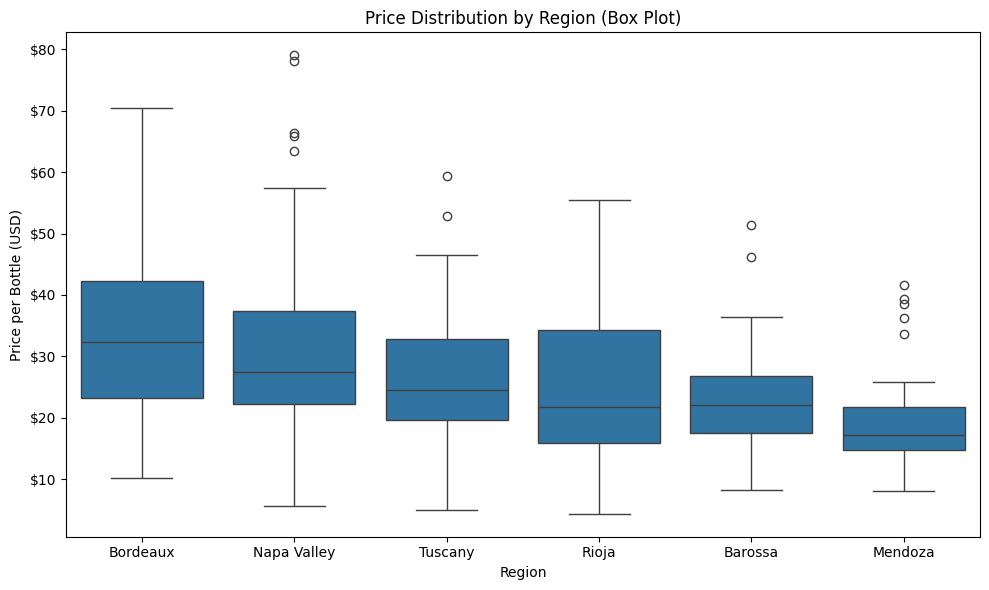

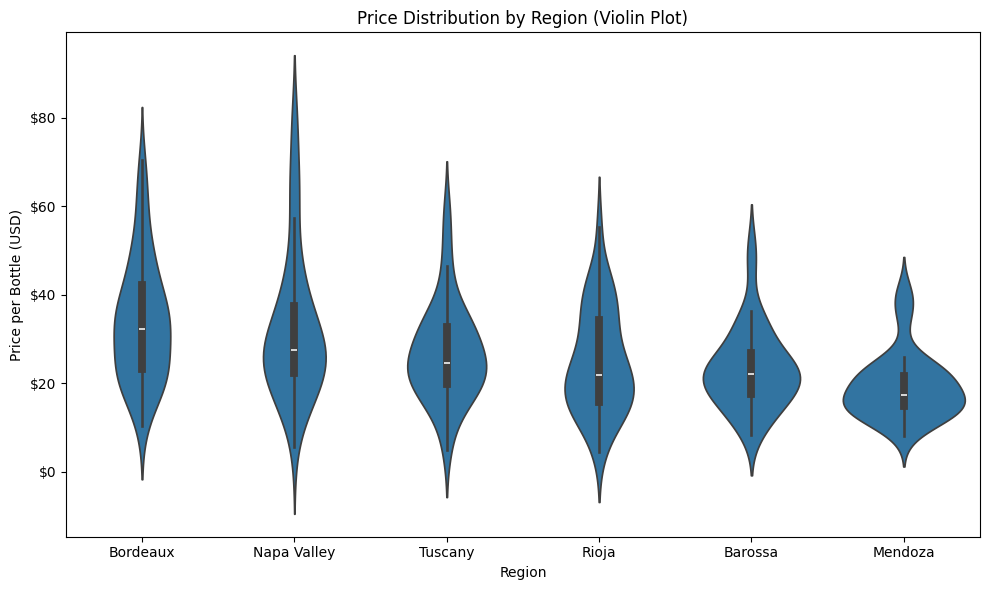

In [41]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: aging years vs quality score scatter + regression line, colored by region
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x='aging_years', y='quality_score', data=df, hue='region', ax=ax)
sns.regplot(x='aging_years', y='quality_score', data=df, scatter=False, line_kws={'color': 'red'}, ax=ax)
ax.set_title('Aging Years vs Quality Score (red line: all wines)')
ax.set_xlabel('Aging (years)')
ax.set_ylabel('Quality Score (0-100)')
ax.legend(title='Region')
plt.tight_layout()
plt.show()

# Chart 2: price distribution by region, same order as the Q2 table
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='region', y='price', data=df, order=avg_price_by_region.index, ax=ax)
ax.set_title('Price Distribution by Region (Box Plot)')
ax.set_xlabel('Region')
ax.set_ylabel('Price per Bottle (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(x='region', y='price', data=df, order=avg_price_by_region.index, ax=ax)
ax.set_title('Price Distribution by Region (Violin Plot)')
ax.set_xlabel('Region')
ax.set_ylabel('Price per Bottle (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Aging and quality score move together, with a correlation of **0.886**.  
  (숙성연수와 품질점수는 함께 움직이며 상관계수는 **0.886**입니다.)  
- Quality score and price also move together, with a correlation of **0.883**.  
  (품질점수와 가격도 함께 움직이며 상관계수는 **0.883**입니다.)  
- Bordeaux is the priciest region at **$34.03** on average, and Mendoza is the cheapest at **$19.39**.  
  (Bordeaux가 평균 **$34.03**으로 가장 비싼 산지이고, Mendoza가 **$19.39**로 가장 저렴합니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat aging as a way to raise quality, since its correlation with quality is **0.886**.  
   (숙성연수와 품질의 상관이 **0.886**이므로, 숙성을 품질을 높이는 수단으로 봅니다.)  
2. Price Mendoza wines separately from Bordeaux, since the average gap is **$14.64** per bottle.  
   (평균 차이가 병당 **$14.64**이므로 Mendoza 와인은 Bordeaux와 따로 가격을 정합니다.)  
3. Review the Napa Valley outliers near **$80** before using its average of **$32.48**.  
   (Napa Valley 평균 **$32.48**을 쓰기 전에 **$80** 근처의 이상치를 살펴봅니다.)  


---
# ✅ What I Learned
*Today's biggest lesson*

- A correlation number is not enough, so draw the scatter plot to see whether the points follow a straight line.  
  (상관계수만으로는 부족해서, 산점도를 그려 점이 직선을 따르는지 확인합니다.)  
- A category against a number, such as region and price, is shown with a box plot or a violin plot.  
  (산지와 가격처럼 범주와 숫자는 박스플롯이나 바이올린 플롯으로 봅니다.)  

---
# 🧠 Reflection

**What was difficult?**  
Deciding what to draw for Question 2.  
(Question 2에서 무엇을 그릴지 정하는 것)

**Why?**  
Question 2 compares an average across regions, so there is no correlation or scatter plot to check.  
(Question 2는 산지별 평균 비교라서 확인할 상관계수나 산점도가 없음)

**How did I solve it?**  
Used the box plot and violin plot in Chart 2, ordered by the Question 2 average.  
(Question 2 평균 순서로 Chart 2의 박스플롯과 바이올린 플롯을 씀)

**What would I do differently next time?**  
Pick the chart by the column types, a category with a number for a box plot and two numbers for a scatter plot.  
(열 유형으로 차트를 고르기. 범주와 숫자는 박스플롯, 숫자 둘은 산점도)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I can choose a scatter plot or a box plot from the column types.  
(열 유형에 따라 산점도나 박스플롯을 고를 수 있습니다.)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 65: SQL window functions  
  (Day 65: SQL 윈도우 함수)  
